# 현실의 데이터 19: 지진: 시공간 데이터

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/SuminHan/book-ml/blob/main/notebooks/datashop/19_earthquakes.ipynb)

**분야**: 도시 · 공간 &nbsp;|&nbsp; **이 분야에서 먼저 보는 문제**: 시공간 (spatiotemporal) 데이터 · 재난 · 안전 · 위험 지도

> 2023~2024년 전 세계 규모 4.5 이상 지진 1만 4천 개. 다음 주, 어느 지역에서 지진이 날까?

**데이터**: USGS Earthquake Catalog (ComCat) (약 3MB). 미국 지질조사국 (USGS) ANSS 통합 지진 목록, FDSN API 로 2023-01-01 ~ 2024-12-31 규모 4.5 이상 14,048개: 시각 · 위도 · 경도 · 깊이 · 규모.

인턴 · 산학협력 과제에서 처음 받게 될 데이터와 닮은 공개 데이터다. 데이터를 열어 보고, 아래 예시처럼 문제 하나를 정해 기준선과 비교한 뒤, 맨 끝의 **나의 다섯 칸** 을 채운다 (1주 2차시 '문제 정형화와 평가지표').

| 칸 | 이 노트북의 예시 |
|---|---|
| ① 한 행 | 격자 칸 (위도 10° × 경도 10°) × 한 주 |
| ② 입력 X | 그 칸의 지난 지진 수 (지난주 · 지난 4주 · 지난해) |
| ③ 출력 y | 다음 주에 규모 4.5 이상 지진이 있나 |
| ④ 평가지표 | 정밀도 · 재현율, ROC-AUC |
| ⑤ 기준선 | '지난주에 있었으면 이번 주도' |

**논문 · 출처** (직접 열어 보자: 이 데이터를 누가, 왜, 어떻게 만들었나):
- [U.S. Geological Survey (2017) Advanced National Seismic System (ANSS) Comprehensive Catalog](https://doi.org/10.5066/F7MS3QZH)

In [1]:
import io, os, zipfile, urllib.request
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

def download(url, path):
    """Download url to path once (skip if it already exists)"""
    os.makedirs(os.path.dirname(path) or ".", exist_ok=True)
    if not os.path.exists(path):
        req = urllib.request.Request(url, headers={"User-Agent": "Mozilla/5.0 (ML course data shop)"})
        with urllib.request.urlopen(req, timeout=600) as r, open(path, "wb") as f:
            f.write(r.read())
    return path

## 입장: 데이터 받기

USGS 의 공개 API 로 바로 받는다 (2년, 규모 4.5 이상).

In [2]:
URL = ("https://earthquake.usgs.gov/fdsnws/event/1/query?format=csv&starttime=2023-01-01&endtime=2025-01-01"
       "&minmagnitude=4.5&orderby=time-asc")
df = pd.read_csv(download(URL, "data/usgs_2023_2025.csv"), parse_dates=["time"])
print(df.shape)
df[["time", "latitude", "longitude", "depth", "mag", "place"]].sample(5, random_state=0)

(14048, 22)


,time,latitude,longitude,depth,mag,place
9752,2024-04-22 11:18:47.723000+00:00,0.7313,123.8229,265.510,4.7,"74 km WNW of Modisi, Indonesia"
10605,2024-06-03 22:39:24.562000+00:00,-16.4874,-174.8082,256.109,4.5,"123 km WSW of Hihifo, Tonga"
7807,2024-01-07 00:05:13.360000+00:00,8.1321,126.9585,35.000,4.6,"57 km E of Barcelona, Philippines"
321,2023-01-17 02:09:35.617000+00:00,-3.9013,128.4635,128.221,4.8,"38 km SE of Ambon, Indonesia"
5133,2023-09-29 03:41:51.793000+00:00,16.1318,-93.6999,112.097,4.5,"7 km NE of Tonalá, Mexico"


## 열어 보기: 지도 위의 점 (시간 = 색)

지구의 판 경계 (불의 고리) 가 보인다. 한 달씩 넘겨 보면 점이 어떻게 움직일까? (웹 페이지의 움직이는 그림)

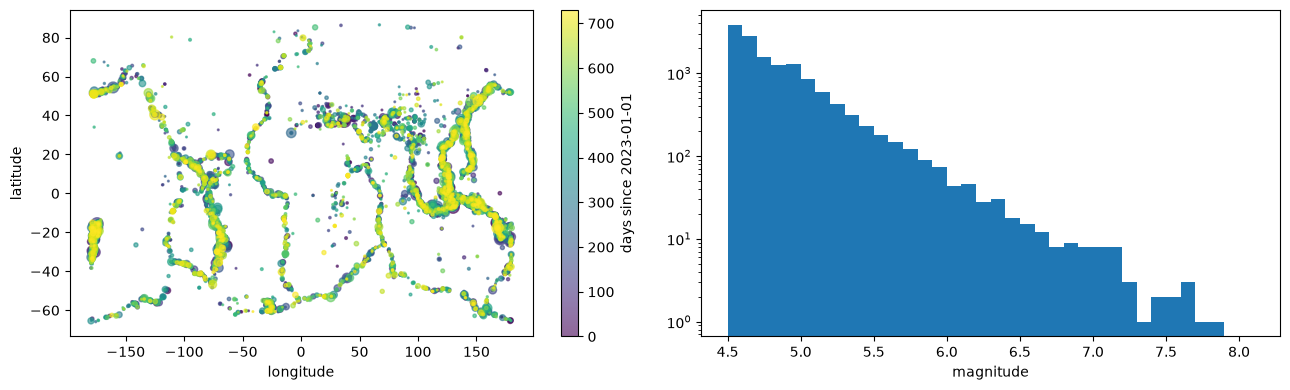

In [3]:
fig, axs = plt.subplots(1, 2, figsize=(13, 4))
t = (df["time"] - df["time"].min()).dt.days
sc = axs[0].scatter(df["longitude"], df["latitude"], c=t, s=(df["mag"] - 4) ** 2 * 6, cmap="viridis", alpha=0.6)
plt.colorbar(sc, ax=axs[0], label="days since 2023-01-01"); axs[0].set_xlabel("longitude"); axs[0].set_ylabel("latitude")
axs[1].hist(df["mag"], bins=np.arange(4.5, 8.2, 0.1)); axs[1].set_yscale("log"); axs[1].set_xlabel("magnitude")
plt.tight_layout(); plt.show()

## 문제 하나 골라 보기: (격자 칸, 주) → 다음 주에 지진이 있나

지구를 10° × 10° 칸으로 나누고, 칸 × 주마다 지진 수를 센다. **2023년으로 학습, 2024년으로 시험** (시간 순서).
- 기준선 1: 전부 '없음'
- 기준선 2: 지난주에 있었으면 '있음'
- 점수: 2023년에 그 칸에서 지진이 난 주의 비율 (자주 나는 곳일수록 높게)

In [4]:
from sklearn.metrics import roc_auc_score

def precision_recall(y_true, y_pred):
    tp = np.sum((y_pred == 1) & (y_true == 1)); fp = np.sum((y_pred == 1) & (y_true == 0)); fn = np.sum((y_pred == 0) & (y_true == 1))
    return (tp / (tp + fp) if tp + fp else 0.0), tp / (tp + fn)

df["cell"] = ((df["latitude"] + 90) // 10).astype(int) * 36 + ((df["longitude"] + 180) // 10).astype(int)
df["week"] = ((df["time"] - pd.Timestamp("2023-01-02", tz="UTC")).dt.days // 7).clip(lower=0)
counts = df.groupby(["cell", "week"]).size().unstack(fill_value=0).reindex(columns=range(df["week"].max() + 1), fill_value=0)
has = (counts > 0).astype(int)
print("cells with at least one quake:", len(has), "| weeks:", has.shape[1])

train_weeks, test_weeks = range(1, 52), range(53, has.shape[1])
rate_2023 = has[list(range(52))].mean(axis=1)                     # share of 2023 weeks with a quake
y_test = np.concatenate([has[w].values for w in test_weeks])
last_week = np.concatenate([has[w - 1].values for w in test_weeks])
score = np.concatenate([rate_2023.values for w in test_weeks])
for name, pred in [("always none", np.zeros_like(y_test)), ("same as last week", last_week), ("2023 rate > 0.5", (score > 0.5).astype(int))]:
    p, r = precision_recall(y_test, pred)
    print(f"{name:18s} accuracy {np.mean(pred == y_test):.1%}  precision {p:.0%}  recall {r:.0%}")
print(f"2023 rate as a score: ROC-AUC {roc_auc_score(y_test, score):.2f}")

cells with at least one quake: 285 | weeks: 105
always none        accuracy 82.6%  precision 0%  recall 0%
same as last week  accuracy 84.0%  precision 54%  recall 54%
2023 rate > 0.5    accuracy 88.9%  precision 80%  recall 48%
2023 rate as a score: ROC-AUC 0.87


**관찰**: '어디서 자주 나는가' 는 꽤 맞힌다. 하지만 이건 **언제** 큰 지진이 날지를 맞히는 게 아니다. 큰 지진의 시각을 미리 맞히는 방법은 아직 없다. 문제를 무엇으로 정했는지 정확히 말해야 하는 이유다.

## 다른 문제로 바꿔 보기

- **조기 경보**: 한 행 = 지진파가 처음 잡힌 몇 초, y = 몇 초 뒤 큰 흔들림이 올 지역. 실제 지진 조기 경보가 이 문제다 (지진파 데이터 STEAD 등).
- 격자를 1° 로 줄이면? 한 행이 늘고 '있음' 은 더 드물어진다. 지표는 어떻게 바뀔까?
- 다른 시공간 데이터: 교통 속도 (도로 × 5분), 미세먼지 (측정소 × 시간), 공유 자전거 (대여소 × 시간).

### 나의 다섯 칸

아래 표를 직접 채워 보자. 위의 예시와 다르게 정해도 된다.

| 칸 | 내가 정한 것 |
|---|---|
| ① 한 행은 무엇? | |
| ② 입력 X (예측할 때 알 수 있는 것만) | |
| ③ 출력 y | |
| ④ 평가지표 | |
| ⑤ 기준선 | |